<a href="https://colab.research.google.com/github/Andronicus7880/AI-and-Bioinformatics/blob/main/transit_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# # Optimizing Public Transit Operations: An EDA of MetroMove Trip Data
# **Sections:** 1 Load & inspect · 2 Clean · 3 Descriptive stats · 4 Univariate · 5 Bivariate · 6 Multivariate · 7 Recommendations



In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configure plotting aesthetics and Pandas display settings
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", None)

trans = "/content/Public_Transport_Trips_EDA.xlsx"  #import dataset
MODE_ORDER = ["Bus", "Train", "Tram", "Ferry"]      # Define a logical display order for transport modes

DAY_ORDER = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]   # Define standard chronological order for days of the week


In [ ]:

# ## 1. Load and inspect the raw data


In [8]:
raw = pd.read_excel(trans)   #read as excel
print("Shape:", raw.shape)   #show the dimensions
raw.head(10)                 #just the first 10


Shape: (1000, 12)


,Trip_ID,Mode_of_Transport,Departure_Station,Arrival_Station,Departure_Time,Passenger_Count,Fare_Amount,Trip_Duration_Minutes,Trip_Date,Day_of_Week,Unnamed: 10,Unnamed: 11
0,TRIP0001,FERRY,West End,airport,2024-01-01 06:00:00,21.00,4.34,26.00,2024-01-01,Sunday,NaN,F
1,TRIP0002,Tram,North Station,Downtown,2024-01-01 06:01:00,46.00,20.67,134.00,2024-01-01,Saturday,NaN,F
2,TRIP0003,bus,Central,North Station,2024-01-01 06:02:00,91.00,NaN,NaN,2024-01-01,Tuesday,NaN,F
3,TRIP0004,FERRY,Downtown,Central,2024-01-01 06:03:00,27.00,3.77,NaN,2024-01-01,Sunday,NaN,F
4,TRIP0005,Ferry,Downtown,Central,2024-01-01 06:04:00,66.00,NaN,NaN,2024-01-01,Monday,NaN,F
5,TRIP0006,fErry,South Point,South Point,2024-01-01 06:05:00,41.00,5.99,50.00,2024-01-01,Thursday,NaN,T
6,TRIP0007,bus,West End,West End,2024-01-01 06:06:00,13.00,40.51,100.00,2024-01-01,Saturday,NaN,T
7,TRIP0008,FERRY,Central,South Point,2024-01-01 06:07:00,9.00,NaN,14.00,2024-01-01,Saturday,NaN,F
8,TRIP0009,Train,West End,North Station,2024-01-01 06:08:00,36.00,4.08,172.00,2024-01-01,Saturday,NaN,F
9,TRIP0010,Ferry,Central,South Point,2024-01-01 06:09:00,86.00,47.78,132.00,2024-01-01,Wednesday,NaN,F


In [9]:
raw.info()      #detailed information


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Trip_ID                1000 non-null   object        
 1   Mode_of_Transport      1000 non-null   object        
 2   Departure_Station      1000 non-null   object        
 3   Arrival_Station        1000 non-null   object        
 4   Departure_Time         1000 non-null   datetime64[ns]
 5   Passenger_Count        900 non-null    float64       
 6   Fare_Amount            900 non-null    float64       
 7   Trip_Duration_Minutes  900 non-null    float64       
 8   Trip_Date              1000 non-null   datetime64[ns]
 9   Day_of_Week            1000 non-null   object        
 10  Unnamed: 10            0 non-null      float64       
 11  Unnamed: 11            299 non-null    object        
dtypes: datetime64[ns](2), float64(4), object(6)
memory usage: 93.9+

In [10]:
# Missing values and a first look at the messy categorical columns
print(raw.isna().sum(), "")
for col in ["Mode_of_Transport", "Departure_Station", "Arrival_Station", "Day_of_Week"]:
    print(f"--- {col} ---")
    print(raw[col].value_counts(dropna=False).to_string(), "")


Trip_ID                     0
Mode_of_Transport           0
Departure_Station           0
Arrival_Station             0
Departure_Time              0
Passenger_Count           100
Fare_Amount               100
Trip_Duration_Minutes     100
Trip_Date                   0
Day_of_Week                 0
Unnamed: 10              1000
Unnamed: 11               701
dtype: int64 
--- Mode_of_Transport ---
Mode_of_Transport
Bus      147
Tram     138
bus      137
train    123
Train    120
FERRY    119
Ferry    118
fErry     50
BUS       48 
--- Departure_Station ---
Departure_Station
North Station    171
Downtown         167
West End         159
Central          158
Airport          157
South Point      138
 Central          50 
--- Arrival_Station ---
Arrival_Station
South Point      171
Downtown         168
West End         163
Airport          163
Central          160
North Station    125
airport           50 
--- Day_of_Week ---
Day_of_Week
Sunday       167
Tuesday      147
Saturday     146
M

In [ ]:

# **Issues spotted in the raw file**
# - `Mode_of_Transport`: 9 spellings for 4 modes (`bus`, `BUS`, `fErry`...).
# - `Departure_Station`: leading/trailing whitespace (e.g. `" Central"`); `Arrival_Station`: casing (`airport`).
# - ~10% missing in each of `Passenger_Count`, `Fare_Amount`, `Trip_Duration_Minutes`.
# - Two stray unnamed columns (a spreadsheet helper formula), which are not part of the data dictionary.
# - Check below: `Departure_Time` and `Trip_Date`, and `Day_of_Week` and `Trip_Date`, may disagree.


# **Issues spotted in the raw file**
# - `Mode_of_Transport`: 9 spellings for 4 modes (`bus`, `BUS`, `fErry`...).
# - `Departure_Station`: leading/trailing whitespace (e.g. `" Central"`); `Arrival_Station`: casing (`airport`).
# - ~10% missing in each of `Passenger_Count`, `Fare_Amount`, `Trip_Duration_Minutes`.
# - Two stray unnamed columns (a spreadsheet helper formula), which are not part of the data dictionary.
# - Check below: `Departure_Time` and `Trip_Date`, and `Day_of_Week` and `Trip_Date`, may disagree.

In [11]:
# Cross-field consistency checks
dep_date = raw["Departure_Time"].dt.normalize()
print("Unique dates in Departure_Time:", dep_date.nunique())
print("Departure_Time date != Trip_Date:", (dep_date != raw["Trip_Date"]).sum(), "rows")
print("Day_of_Week != weekday of Trip_Date: "
      f"{(raw['Trip_Date'].dt.day_name() != raw['Day_of_Week']).mean():.0%} of rows")


Unique dates in Departure_Time: 1
Departure_Time date != Trip_Date: 976 rows
Day_of_Week != weekday of Trip_Date: 85% of rows


In [ ]:

# **Finding:** every `Departure_Time` falls on 2024-01-01 (only the clock time varies), and the stored
# `Day_of_Week` rarely matches `Trip_Date`. So:
# - **Date** analysis uses `Trip_Date`; **time-of-day** analysis uses the hour from `Departure_Time`.
# - `Day_of_Week` is recomputed from `Trip_Date`; the original is kept as `Day_of_Week_Original`.


# **Finding:** every `Departure_Time` falls on 2024-01-01 (only the clock time varies), and the stored
# `Day_of_Week` rarely matches `Trip_Date`. So:
# - **Date** analysis uses `Trip_Date`; **time-of-day** analysis uses the hour from `Departure_Time`.
# - `Day_of_Week` is recomputed from `Trip_Date`; the original is kept as `Day_of_Week_Original`.

In [ ]:

# ## 2. Data cleaning


# ## 2. Data cleaning

In [12]:
df = raw.copy()

# 2.1 Drop the stray helper columns
df = df.loc[:, ~df.columns.str.startswith("Unnamed")]

# 2.2 Standardise text fields
df["Mode_of_Transport"] = df["Mode_of_Transport"].str.strip().str.title()
for col in ["Departure_Station", "Arrival_Station"]:
    df[col] = df[col].str.strip().str.title()

# 2.3 Duplicates
print("Duplicate Trip_IDs:", df["Trip_ID"].duplicated().sum())
print("Fully duplicated rows:", df.duplicated().sum())
df = df.drop_duplicates()

# 2.4 Fix dates / day of week
df["Day_of_Week_Original"] = df["Day_of_Week"]
df["Day_of_Week"] = pd.Categorical(df["Trip_Date"].dt.day_name(), categories=DAY_ORDER, ordered=True)

# 2.5 Feature engineering
df["Departure_Hour"] = df["Departure_Time"].dt.hour
df["Time_Period"] = pd.cut(
    df["Departure_Hour"], bins=[5, 9, 15, 19, 23],
    labels=["Morning peak (6-9)", "Midday (10-15)", "Evening peak (16-19)", "Night (20-23)"])
df["Is_Weekend"] = df["Day_of_Week"].isin(["Saturday", "Sunday"])
df["Week"] = df["Trip_Date"].dt.isocalendar().week.astype(int)
df["Same_Station"] = df["Departure_Station"] == df["Arrival_Station"]
df["Route"] = df["Departure_Station"] + " -> " + df["Arrival_Station"]


Duplicate Trip_IDs: 0
Fully duplicated rows: 0


In [13]:
# 2.6 Missing values: keep the NaNs for honest statistics, and build an imputed
# copy (median within each transport mode) for methods that need complete data.
num_cols = ["Passenger_Count", "Fare_Amount", "Trip_Duration_Minutes"]
print("Missing before:", df[num_cols].isna().sum(), "")
print("Rows with at least one missing value:", df[num_cols].isna().any(axis=1).sum())

df_imp = df.copy()
for col in num_cols:
    df_imp[col] = df_imp[col].fillna(df_imp.groupby("Mode_of_Transport")[col].transform("median"))
print("Missing after imputation:", int(df_imp[num_cols].isna().sum().sum()))


Missing before: Passenger_Count          100
Fare_Amount              100
Trip_Duration_Minutes    100
dtype: int64 
Rows with at least one missing value: 267
Missing after imputation: 0


In [14]:
# 2.7 Derived metrics (computed on the original, non-imputed values)
df["Fare_per_Passenger"] = df["Fare_Amount"] / df["Passenger_Count"]
df["Fare_per_Minute"] = df["Fare_Amount"] / df["Trip_Duration_Minutes"]
df["Passenger_Minutes"] = df["Passenger_Count"] * df["Trip_Duration_Minutes"]
df_imp["Fare_per_Passenger"] = df_imp["Fare_Amount"] / df_imp["Passenger_Count"]

# 2.8 Outliers (IQR rule). Flagged, not removed, since removal needs business justification.
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75])
    lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    return ((s < lo) | (s > hi)).sum()

print("IQR outliers:")
for col in num_cols + ["Fare_per_Passenger"]:
    print(f"  {col:<24}{iqr_outliers(df[col].dropna())}")

# 2.9 Same-station trips (departure == arrival)
print(f"\nTrips with identical departure and arrival: {df['Same_Station'].sum()} ({df['Same_Station'].mean():.1%})")


IQR outliers:
  Passenger_Count         0
  Fare_Amount             0
  Trip_Duration_Minutes   0
  Fare_per_Passenger      93

Trips with identical departure and arrival: 164 (16.4%)


In [15]:
print("Cleaned shape:", df.shape)
print("Modes:", sorted(df["Mode_of_Transport"].unique()))
print("Stations:", sorted(df["Departure_Station"].unique()))
df.head()


Cleaned shape: (1000, 20)
Modes: ['Bus', 'Ferry', 'Train', 'Tram']
Stations: ['Airport', 'Central', 'Downtown', 'North Station', 'South Point', 'West End']


,Trip_ID,Mode_of_Transport,Departure_Station,Arrival_Station,Departure_Time,Passenger_Count,Fare_Amount,Trip_Duration_Minutes,Trip_Date,Day_of_Week,Day_of_Week_Original,Departure_Hour,Time_Period,Is_Weekend,Week,Same_Station,Route,Fare_per_Passenger,Fare_per_Minute,Passenger_Minutes
0,TRIP0001,Ferry,West End,Airport,2024-01-01 06:00:00,21.00,4.34,26.00,2024-01-01,Monday,Sunday,6,Morning peak (6-9),False,1,False,West End -> Airport,0.21,0.17,546.00
1,TRIP0002,Tram,North Station,Downtown,2024-01-01 06:01:00,46.00,20.67,134.00,2024-01-01,Monday,Saturday,6,Morning peak (6-9),False,1,False,North Station -> Downtown,0.45,0.15,"6,164.00"
2,TRIP0003,Bus,Central,North Station,2024-01-01 06:02:00,91.00,NaN,NaN,2024-01-01,Monday,Tuesday,6,Morning peak (6-9),False,1,False,Central -> North Station,NaN,NaN,NaN
3,TRIP0004,Ferry,Downtown,Central,2024-01-01 06:03:00,27.00,3.77,NaN,2024-01-01,Monday,Sunday,6,Morning peak (6-9),False,1,False,Downtown -> Central,0.14,NaN,NaN
4,TRIP0005,Ferry,Downtown,Central,2024-01-01 06:04:00,66.00,NaN,NaN,2024-01-01,Monday,Monday,6,Morning peak (6-9),False,1,False,Downtown -> Central,NaN,NaN,NaN


In [ ]:

# ## 3. Descriptive statistics


# ## 3. Descriptive statistics

In [16]:
df[num_cols + ["Fare_per_Passenger", "Fare_per_Minute"]].describe().T


,count,mean,std,min,25%,50%,75%,max
Passenger_Count,900.00,49.15,27.70,1.00,25.00,48.00,72.00,99.00
Fare_Amount,900.00,25.36,14.46,0.50,12.82,25.40,37.87,49.95
Trip_Duration_Minutes,900.00,94.27,50.63,5.00,49.75,97.50,138.00,179.00
Fare_per_Passenger,811.00,1.23,2.86,0.01,0.27,0.52,0.98,36.85
Fare_per_Minute,816.00,0.52,0.85,0.00,0.13,0.27,0.52,9.64


In [17]:
# Skewness and kurtosis
df[num_cols + ["Fare_per_Passenger"]].agg(["skew", "kurt"]).T


,skew,kurt
Passenger_Count,0.07,-1.13
Fare_Amount,-0.03,-1.23
Trip_Duration_Minutes,-0.05,-1.20
Fare_per_Passenger,6.91,63.65


In [18]:
# Summary by transport mode
mode_summary = (df.groupby("Mode_of_Transport", observed=True)
    .agg(trips=("Trip_ID", "count"),
         avg_passengers=("Passenger_Count", "mean"),
         total_passengers=("Passenger_Count", "sum"),
         avg_fare=("Fare_Amount", "mean"),
         total_revenue=("Fare_Amount", "sum"),
         avg_duration=("Trip_Duration_Minutes", "mean"),
         median_duration=("Trip_Duration_Minutes", "median"),
         avg_fare_per_passenger=("Fare_per_Passenger", "mean"))
    .reindex(MODE_ORDER))
mode_summary


,trips,avg_passengers,total_passengers,avg_fare,total_revenue,avg_duration,median_duration,avg_fare_per_passenger
Mode_of_Transport,,,,,,,,
Bus,332,49.13,"14,936.00",25.62,"7,660.72",96.21,100.00,1.21
Train,243,46.91,"9,851.00",26.26,"5,594.00",94.37,99.00,1.75
Tram,138,51.19,"6,348.00",25.24,"3,180.32",95.07,94.00,1.14
Ferry,287,50.02,"13,104.00",24.39,"6,389.63",91.59,93.00,0.90


In [ ]:

# ## 4. Univariate analysis


# ## 4. Univariate analysis

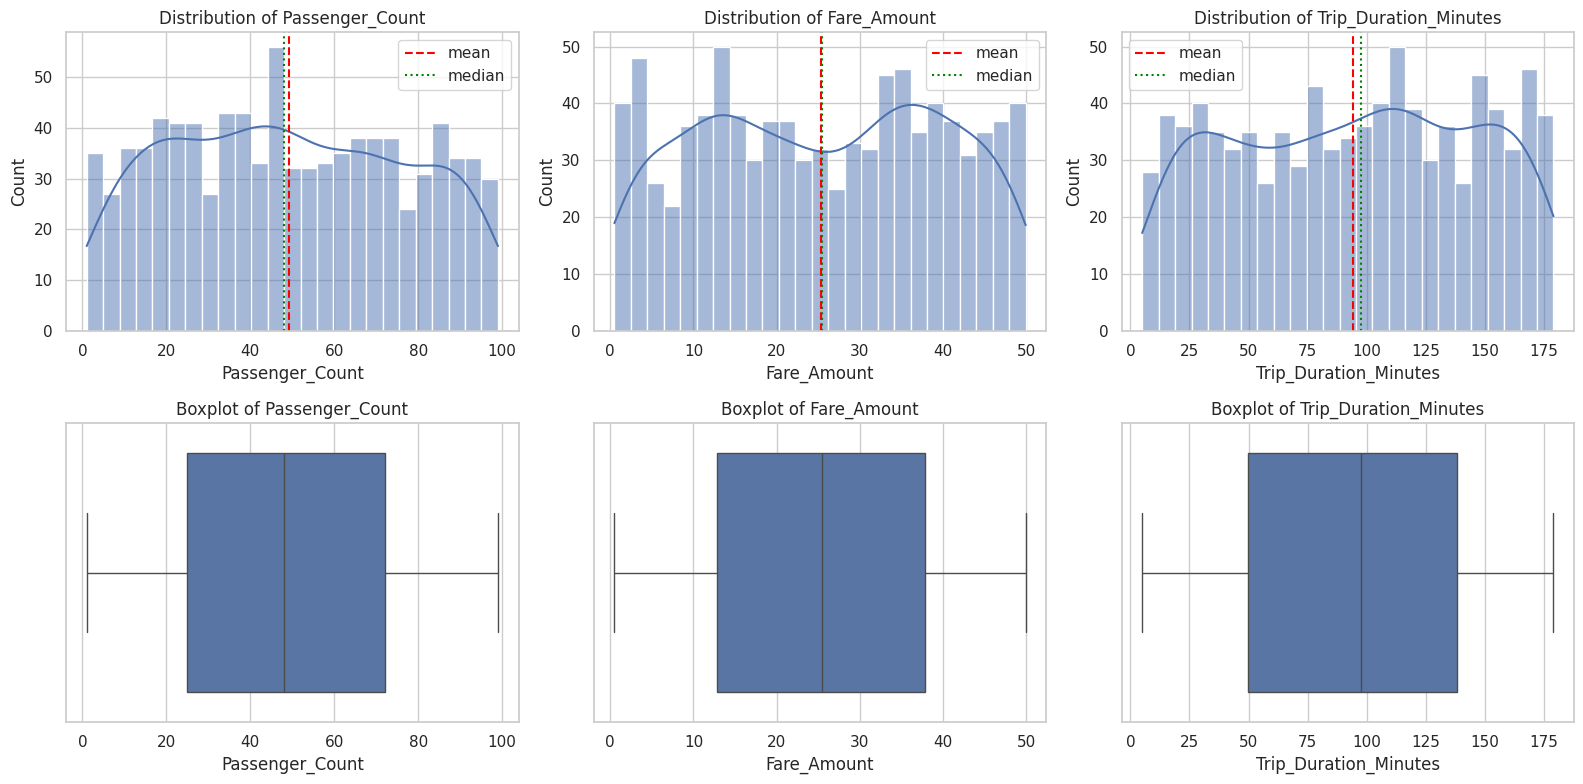

In [19]:
# 4.1 Numeric distributions
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes[0], num_cols):
    sns.histplot(df[col].dropna(), bins=25, kde=True, ax=ax)
    ax.axvline(df[col].mean(), color="red", ls="--", label="mean")
    ax.axvline(df[col].median(), color="green", ls=":", label="median")
    ax.set_title(f"Distribution of {col}")
    ax.legend()
for ax, col in zip(axes[1], num_cols):
    sns.boxplot(x=df[col].dropna(), ax=ax)
    ax.set_title(f"Boxplot of {col}")
plt.tight_layout()
plt.show()


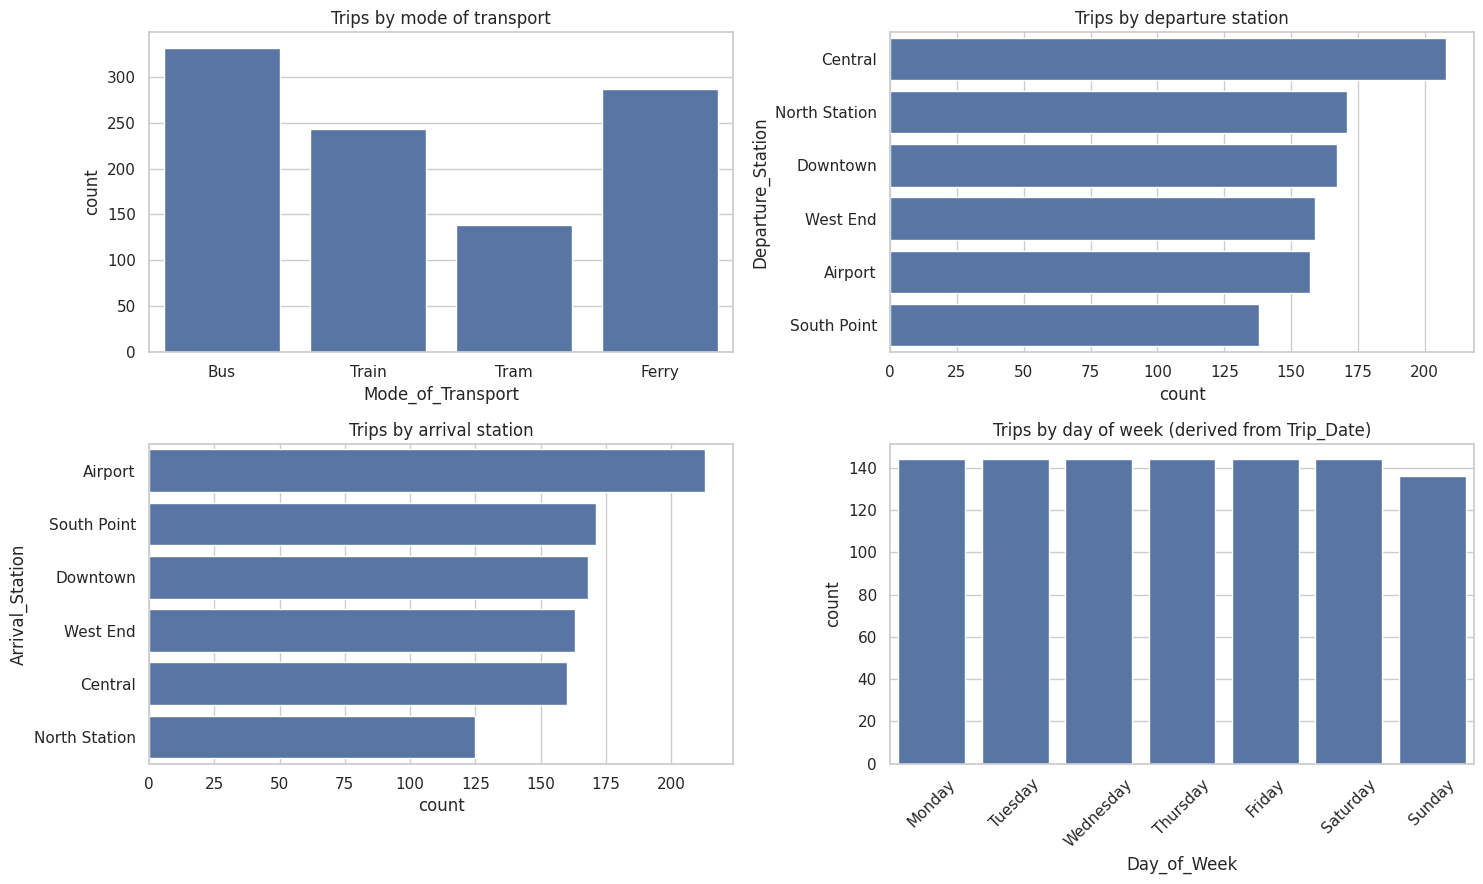

In [20]:
# 4.2 Categorical frequencies
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
sns.countplot(data=df, x="Mode_of_Transport", order=MODE_ORDER, ax=axes[0, 0])
axes[0, 0].set_title("Trips by mode of transport")
sns.countplot(data=df, y="Departure_Station", order=df["Departure_Station"].value_counts().index, ax=axes[0, 1])
axes[0, 1].set_title("Trips by departure station")
sns.countplot(data=df, y="Arrival_Station", order=df["Arrival_Station"].value_counts().index, ax=axes[1, 0])
axes[1, 0].set_title("Trips by arrival station")
sns.countplot(data=df, x="Day_of_Week", order=DAY_ORDER, ax=axes[1, 1])
axes[1, 1].set_title("Trips by day of week (derived from Trip_Date)")
axes[1, 1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()


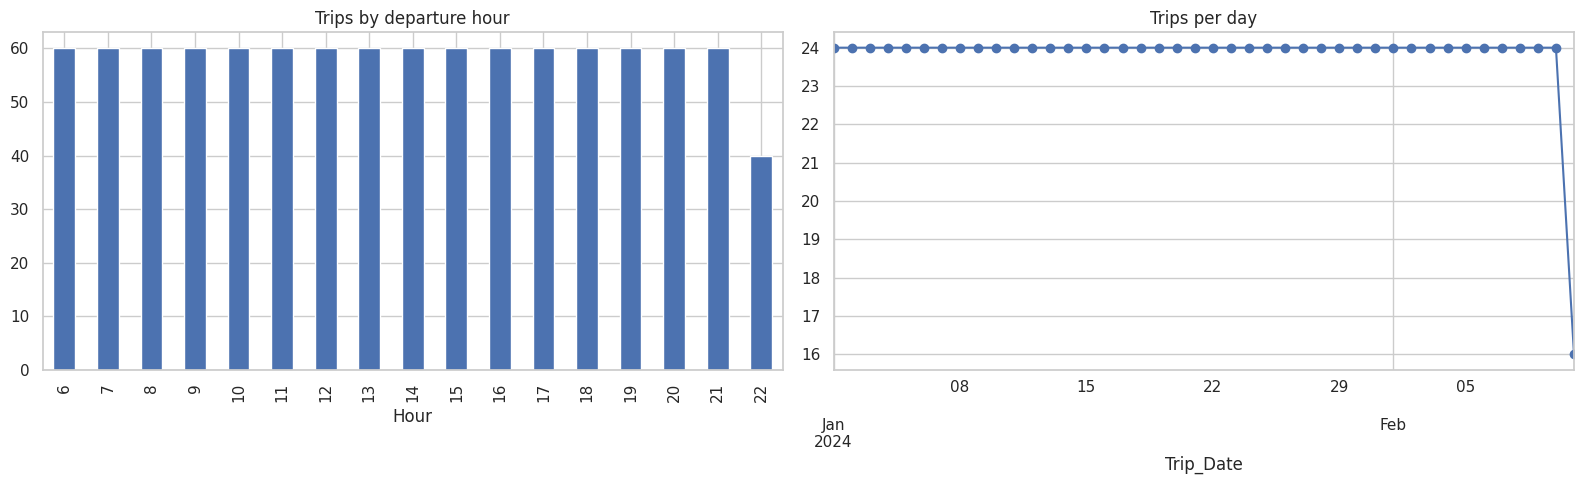

In [21]:
# 4.3 Trips by hour and by date
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
df["Departure_Hour"].value_counts().sort_index().plot(kind="bar", ax=axes[0])
axes[0].set_title("Trips by departure hour")
axes[0].set_xlabel("Hour")
df.groupby("Trip_Date").size().plot(ax=axes[1], marker="o")
axes[1].set_title("Trips per day")
plt.tight_layout()
plt.show()


In [ ]:

# ## 5. Bivariate analysis


# ## 5. Bivariate analysis

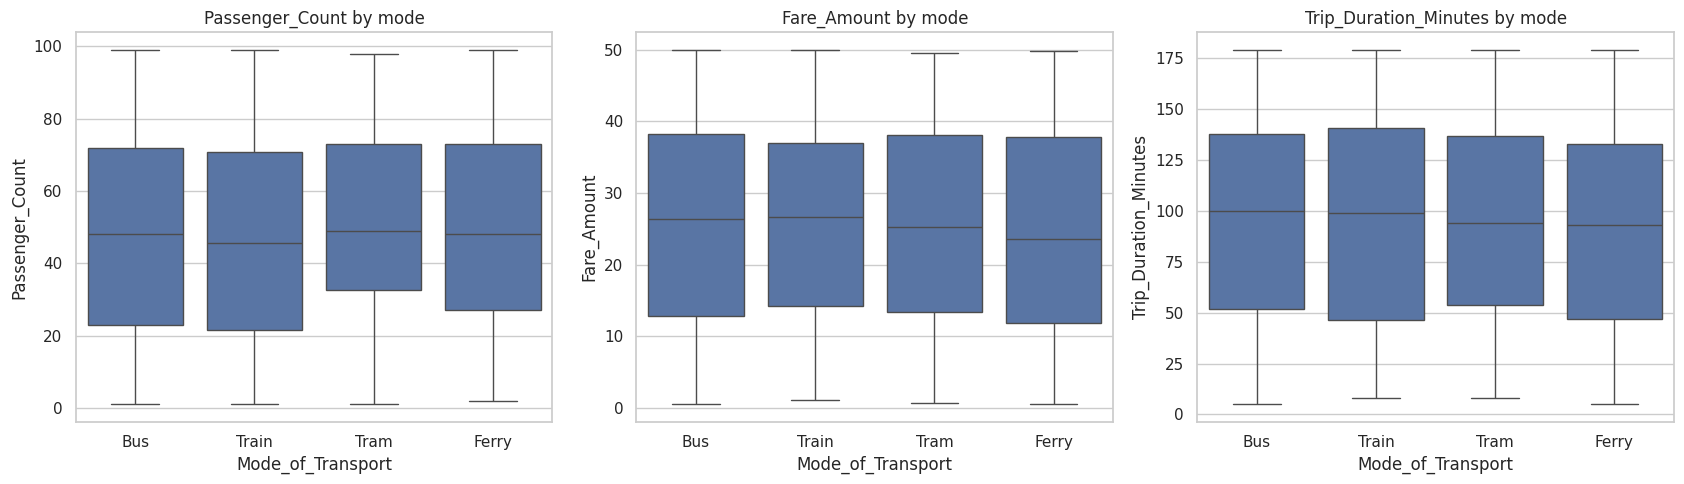

In [22]:
# 5.1 Numeric metrics by mode
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, col in zip(axes, num_cols):
    sns.boxplot(data=df, x="Mode_of_Transport", y=col, order=MODE_ORDER, ax=ax)
    ax.set_title(f"{col} by mode")
plt.tight_layout()
plt.show()


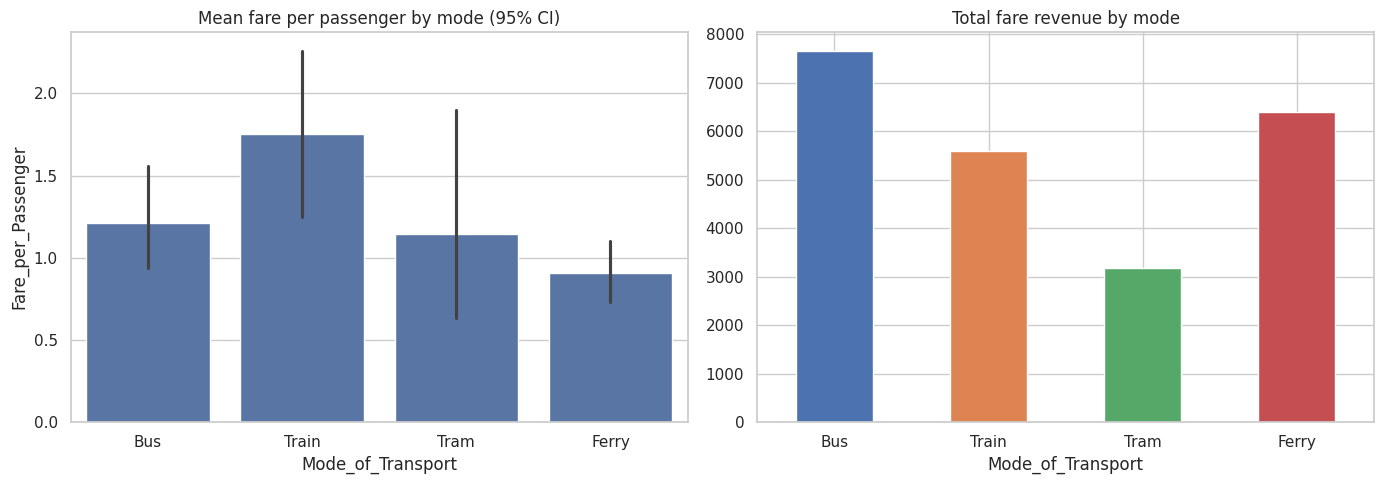

In [23]:
# 5.2 Mode vs mean fare per passenger and total revenue
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=df, x="Mode_of_Transport", y="Fare_per_Passenger", order=MODE_ORDER, errorbar="ci", ax=axes[0])
axes[0].set_title("Mean fare per passenger by mode (95% CI)")
mode_summary["total_revenue"].plot(kind="bar", ax=axes[1], color=sns.color_palette()[:4])
axes[1].set_title("Total fare revenue by mode")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()


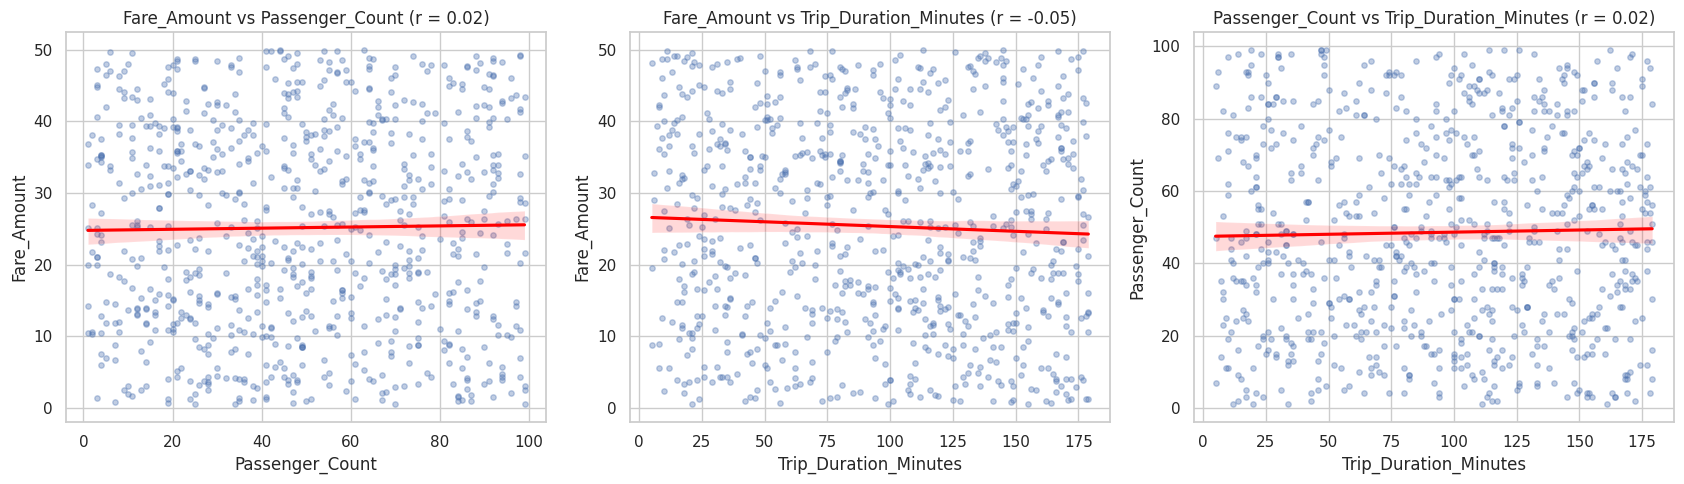

In [24]:
# 5.3 Numeric vs numeric
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
pairs = [("Passenger_Count", "Fare_Amount"),
         ("Trip_Duration_Minutes", "Fare_Amount"),
         ("Trip_Duration_Minutes", "Passenger_Count")]
for ax, (x, y) in zip(axes, pairs):
    sns.regplot(data=df, x=x, y=y, scatter_kws={"alpha": .35, "s": 15}, line_kws={"color": "red"}, ax=ax)
    r = df[[x, y]].corr().iloc[0, 1]
    ax.set_title(f"{y} vs {x} (r = {r:.2f})")
plt.tight_layout()
plt.show()


/tmp/ipykernel_11325/274277714.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[2].set_xticklabels(["Weekday", "Weekend"])


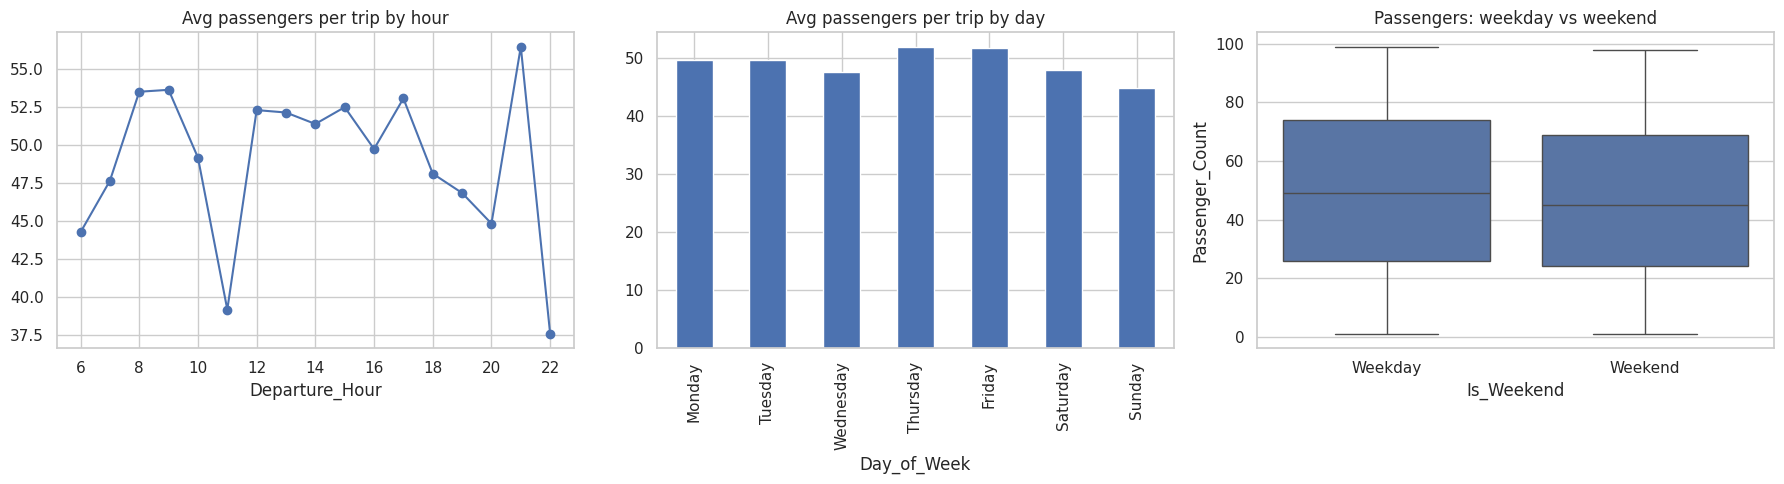

In [25]:
# 5.4 Demand patterns: hour, day, weekday vs weekend
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
df.groupby("Departure_Hour")["Passenger_Count"].mean().plot(marker="o", ax=axes[0])
axes[0].set_title("Avg passengers per trip by hour")
df.groupby("Day_of_Week", observed=True)["Passenger_Count"].mean().reindex(DAY_ORDER).plot(kind="bar", ax=axes[1])
axes[1].set_title("Avg passengers per trip by day")
sns.boxplot(data=df, x="Is_Weekend", y="Passenger_Count", ax=axes[2])
axes[2].set_xticklabels(["Weekday", "Weekend"])
axes[2].set_title("Passengers: weekday vs weekend")
plt.tight_layout()
plt.show()


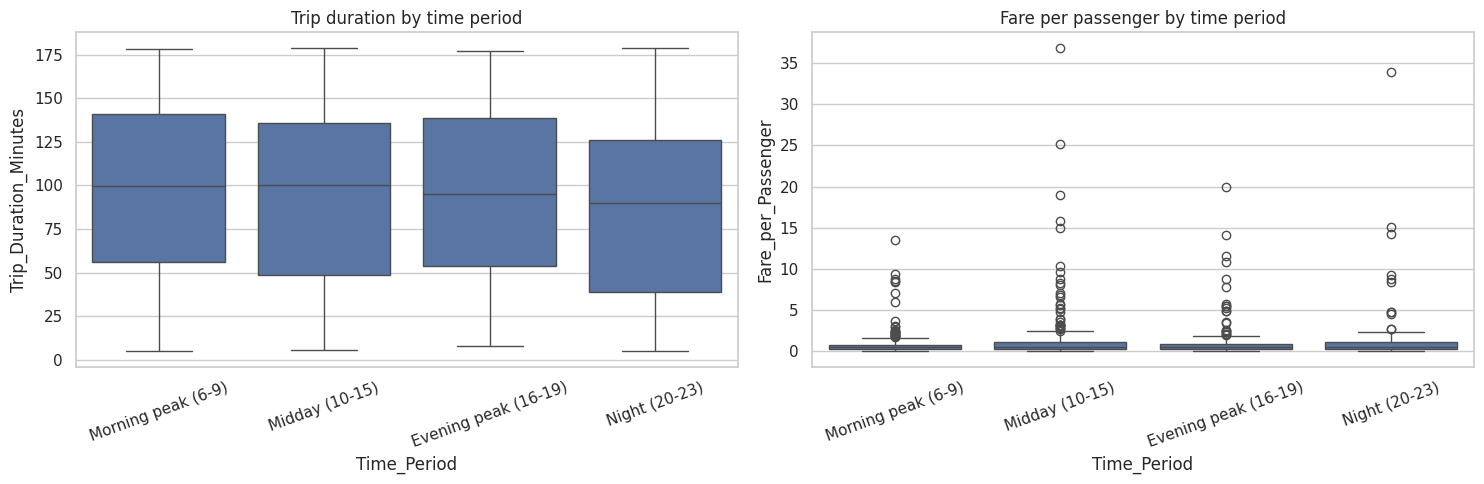

In [26]:
# 5.4b Trip duration over the day, by time period
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=df, x="Time_Period", y="Trip_Duration_Minutes", ax=axes[0])
axes[0].set_title("Trip duration by time period")
axes[0].tick_params(axis="x", rotation=20)
sns.boxplot(data=df, x="Time_Period", y="Fare_per_Passenger", ax=axes[1])
axes[1].set_title("Fare per passenger by time period")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()


,departures,passengers,arrivals,net_flow
Departure_Station,,,,
Central,208,"9,910.00",160,48
North Station,171,"7,304.00",125,46
Downtown,167,"7,087.00",168,-1
West End,159,"6,944.00",163,-4
Airport,157,"6,888.00",213,-56
South Point,138,"6,106.00",171,-33


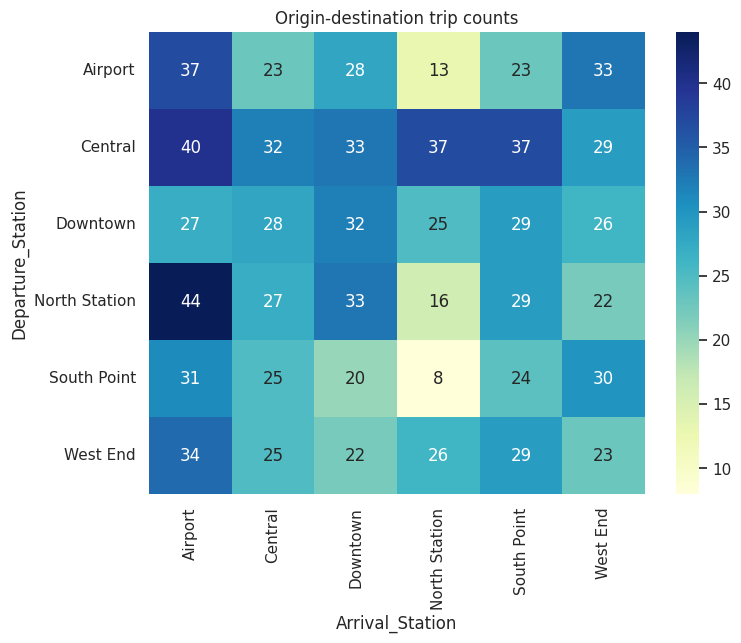

In [27]:
# 5.5 Station analysis
dep = df.groupby("Departure_Station").agg(departures=("Trip_ID", "count"), passengers=("Passenger_Count", "sum"))
arr = df.groupby("Arrival_Station").agg(arrivals=("Trip_ID", "count"))
stations = dep.join(arr)
stations["net_flow"] = stations["departures"] - stations["arrivals"]
display(stations.sort_values("passengers", ascending=False))

# Origin-destination matrix (trip counts)
od = pd.crosstab(df["Departure_Station"], df["Arrival_Station"])
plt.figure(figsize=(8, 6))
sns.heatmap(od, annot=True, fmt="d", cmap="YlGnBu")
plt.title("Origin-destination trip counts")
plt.show()


In [28]:
# 5.6 Statistical tests (does the pattern hold beyond chance?)
from scipy import stats

# Do the modes differ on duration, fare per passenger, and passenger count? (one-way ANOVA + Kruskal-Wallis)
for col in ["Trip_Duration_Minutes", "Fare_per_Passenger", "Passenger_Count"]:
    groups = [g[col].dropna() for _, g in df.groupby("Mode_of_Transport", observed=True)]
    f, p_anova = stats.f_oneway(*groups)
    h, p_kw = stats.kruskal(*groups)
    print(f"{col:<24} ANOVA p={p_anova:.3f} | Kruskal-Wallis p={p_kw:.3f}")

# Weekday vs weekend passengers
wk = df.loc[~df["Is_Weekend"], "Passenger_Count"].dropna()
we = df.loc[df["Is_Weekend"], "Passenger_Count"].dropna()
print("\nWeekday vs weekend passengers (Welch t-test): p =", round(stats.ttest_ind(wk, we, equal_var=False).pvalue, 3))

# Is mode associated with time period? (chi-square)
ct = pd.crosstab(df["Mode_of_Transport"], df["Time_Period"])
print("Mode vs time period (chi-square): p =", round(stats.chi2_contingency(ct)[1], 3))


Trip_Duration_Minutes    ANOVA p=0.753 | Kruskal-Wallis p=0.737
Fare_per_Passenger       ANOVA p=0.024 | Kruskal-Wallis p=0.086
Passenger_Count          ANOVA p=0.512 | Kruskal-Wallis p=0.487

Weekday vs weekend passengers (Welch t-test): p = 0.066
Mode vs time period (chi-square): p = 0.171


In [ ]:

# ## 6. Multivariate analysis


# ## 6. Multivariate analysis

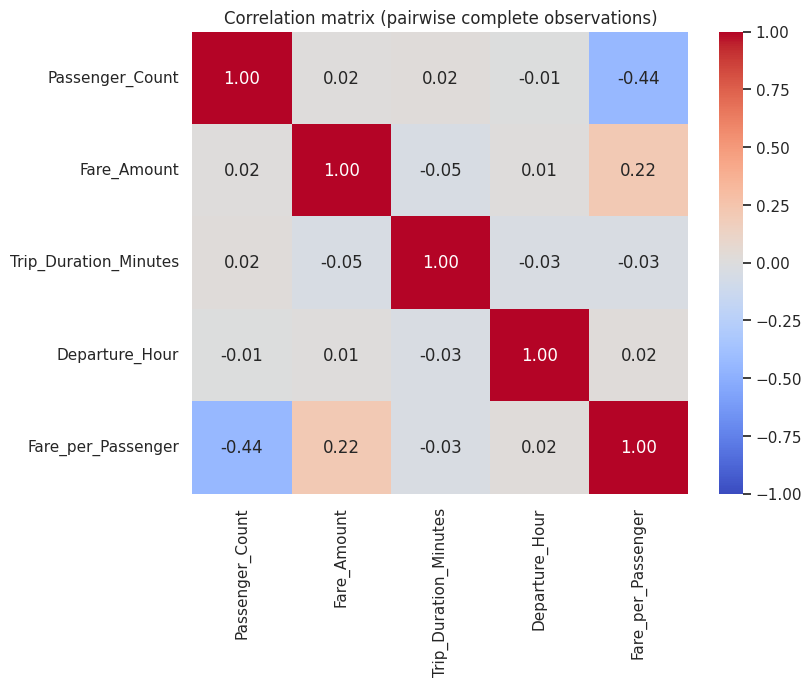

In [29]:
# 6.1 Correlation matrix
corr_cols = ["Passenger_Count", "Fare_Amount", "Trip_Duration_Minutes", "Departure_Hour", "Fare_per_Passenger"]
plt.figure(figsize=(8, 6))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation matrix (pairwise complete observations)")
plt.show()


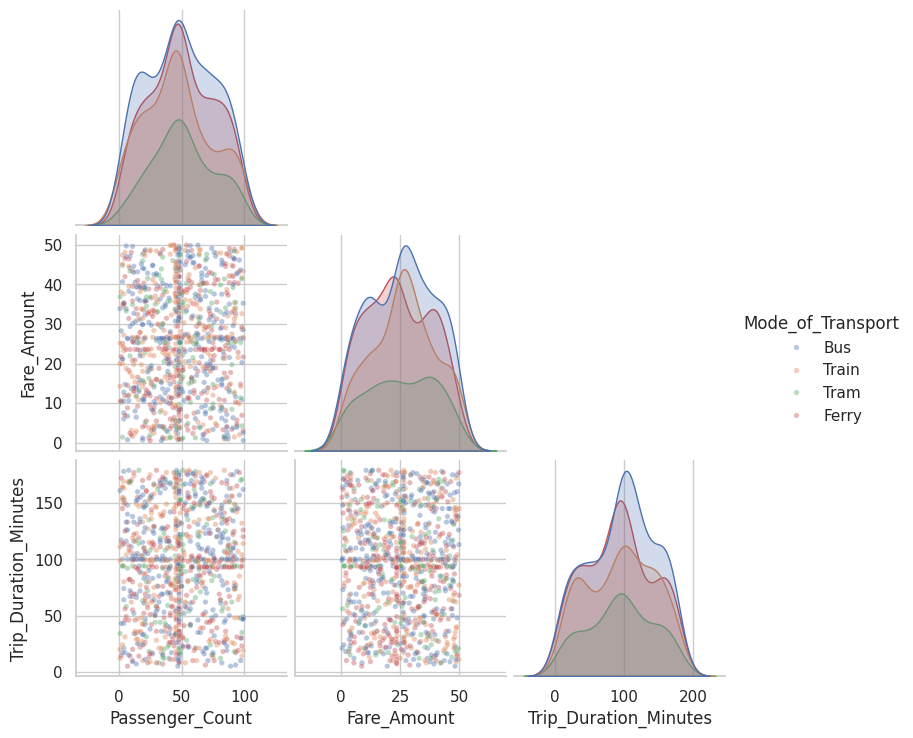

In [30]:
# 6.2 Pairplot by mode
sns.pairplot(df_imp, vars=["Passenger_Count", "Fare_Amount", "Trip_Duration_Minutes"],
             hue="Mode_of_Transport", hue_order=MODE_ORDER, plot_kws={"alpha": .4, "s": 15}, corner=True)
plt.show()


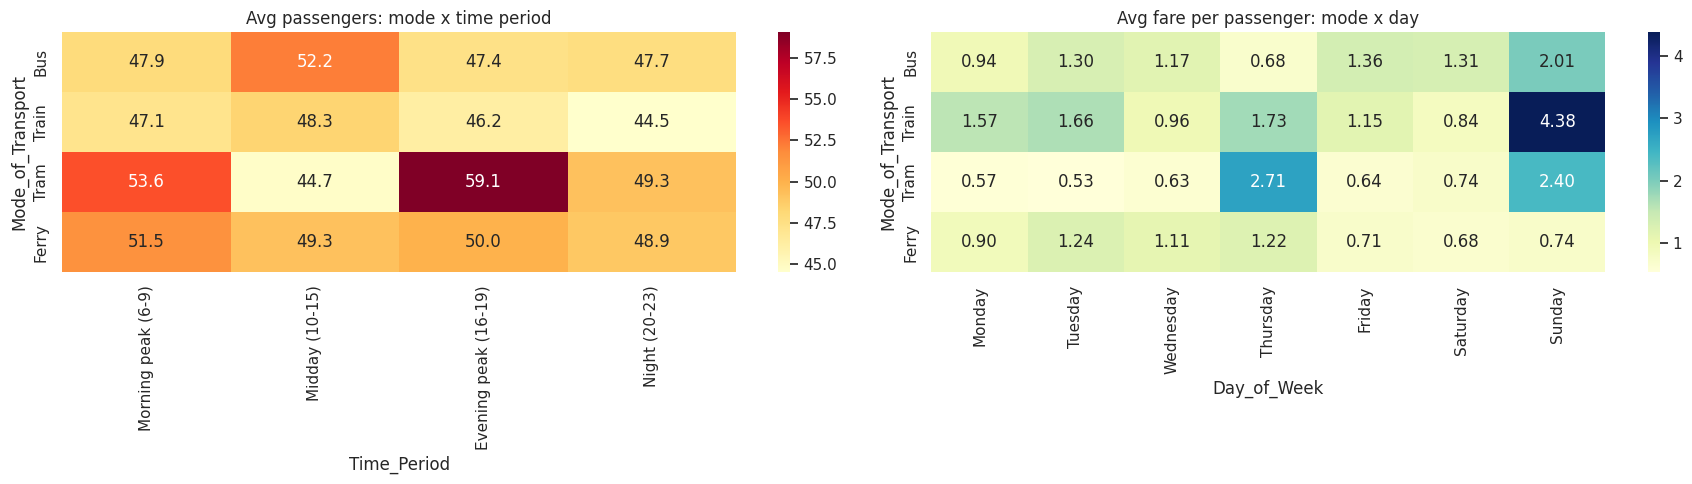

In [31]:
# 6.3 Mode x time period and mode x day heatmaps
pivot_pass = df.pivot_table(index="Mode_of_Transport", columns="Time_Period", values="Passenger_Count",
                            aggfunc="mean", observed=True).reindex(MODE_ORDER)
pivot_fare = df.pivot_table(index="Mode_of_Transport", columns="Day_of_Week", values="Fare_per_Passenger",
                            aggfunc="mean", observed=True).reindex(MODE_ORDER)
fig, axes = plt.subplots(1, 2, figsize=(18, 5))
sns.heatmap(pivot_pass, annot=True, fmt=".1f", cmap="YlOrRd", ax=axes[0])
axes[0].set_title("Avg passengers: mode x time period")
sns.heatmap(pivot_fare, annot=True, fmt=".2f", cmap="YlGnBu", ax=axes[1])
axes[1].set_title("Avg fare per passenger: mode x day")
plt.tight_layout()
plt.show()


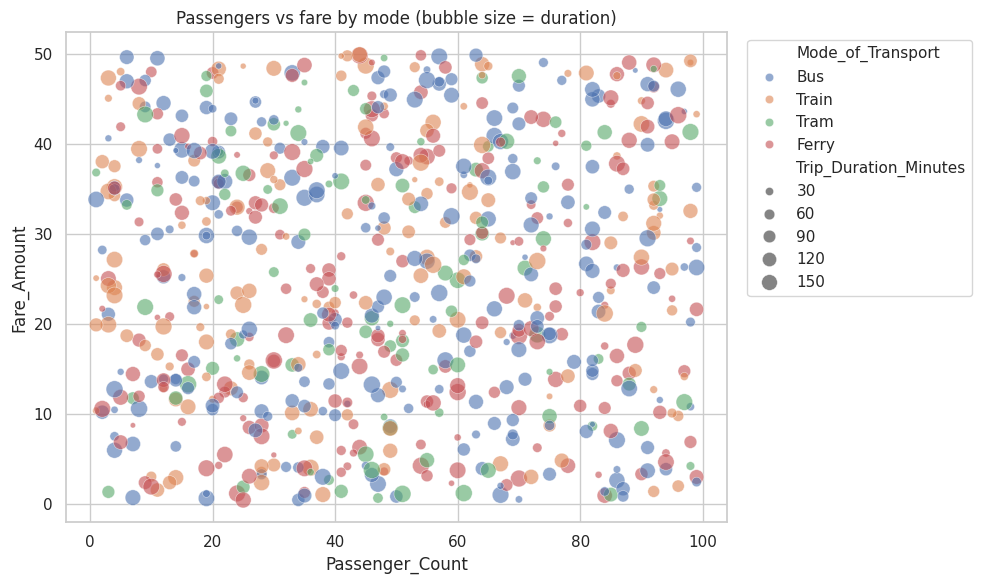

In [32]:
# 6.4 Passengers vs fare, coloured by mode and sized by duration
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="Passenger_Count", y="Fare_Amount", hue="Mode_of_Transport",
                hue_order=MODE_ORDER, size="Trip_Duration_Minutes", sizes=(15, 150), alpha=.6)
plt.title("Passengers vs fare by mode (bubble size = duration)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


In [33]:
# 6.5 Top and bottom routes by volume and revenue (routes with a distinct origin and destination)
routes = (df[~df["Same_Station"]].groupby("Route")
          .agg(trips=("Trip_ID", "count"), passengers=("Passenger_Count", "sum"),
               revenue=("Fare_Amount", "sum"), avg_duration=("Trip_Duration_Minutes", "mean")))
print("Top 10 routes by passengers"); display(routes.sort_values("passengers", ascending=False).head(10))
print("Bottom 5 routes by passengers"); display(routes.sort_values("passengers").head(5))


Top 10 routes by passengers


,trips,passengers,revenue,avg_duration
Route,,,,
North Station -> Airport,44,"1,907.00",964.85,93.81
Central -> South Point,37,"1,772.00","1,006.14",87.67
North Station -> Downtown,33,"1,763.00",602.65,83.81
Central -> North Station,37,"1,757.00",701.99,103.04
Central -> Airport,40,"1,735.00","1,035.14",93.94
West End -> Airport,34,"1,635.00",799.57,89.06
Central -> West End,29,"1,581.00",660.55,86.30
Central -> Downtown,33,"1,569.00",819.85,91.78
Airport -> West End,33,"1,479.00",831.40,96.52


Bottom 5 routes by passengers


,trips,passengers,revenue,avg_duration
Route,,,,
South Point -> North Station,8,462.00,167.34,99.17
Airport -> North Station,13,568.00,384.97,97.15
Airport -> South Point,23,764.00,493.26,87.19
North Station -> West End,22,853.00,452.48,73.95
West End -> Downtown,22,901.00,525.80,106.55


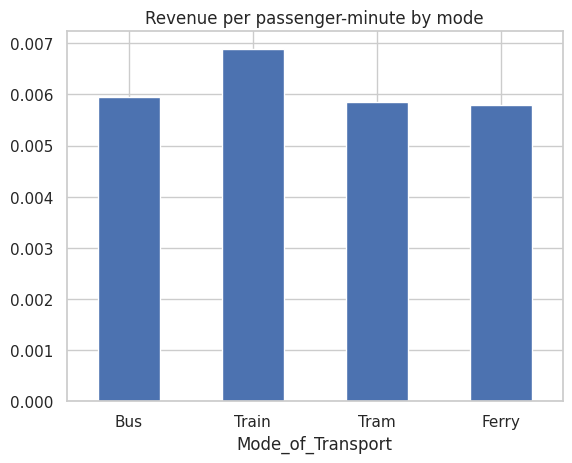

,revenue_per_passenger_minute
Mode_of_Transport,
Bus,0.01
Train,0.01
Tram,0.01
Ferry,0.01


In [34]:
# 6.6 Efficiency: revenue per passenger-minute by mode
eff = (df.groupby("Mode_of_Transport", observed=True)
         .apply(lambda g: g["Fare_Amount"].sum() / g["Passenger_Minutes"].sum(), include_groups=False)
         .reindex(MODE_ORDER).rename("revenue_per_passenger_minute"))
eff.plot(kind="bar", title="Revenue per passenger-minute by mode", rot=0)
plt.show()
eff


In [35]:
# Export the cleaned data for reuse
df.to_csv("Public_Transport_Trips_Cleaned.csv", index=False)
print("Saved cleaned dataset:", df.shape)


Saved cleaned dataset: (1000, 20)
